# Lab 4 (June 29 and July 14 version): Download and Access Sentinel-2 Data

**Name: Gaurav Parajuli**

**Date: 11/10/2026**

---

This notebook prepares the Sentinel-2 image data used in later labs. It does four things:

1. Shows how to get Sentinel-2 Level-2A scenes, either by **downloading them by hand** from the Copernicus Browser or **with code** (a STAC search, then a download).
2. **Clips** each scene to the area of interest (AOI), `aoi_upper_neosho.gpkg`, which runs from Emporia to John Redmond Reservoir.
3. **Saves** small, analysis-ready GeoTIFF stacks that later labs read.
4. Shows how to read the AOI **straight from the cloud** without downloading anything (streaming and a data cube).

| Date (2019) | Role in the course |
|---|---|
| April 20 | Pre-flood baseline |
| May 10 | Flood on the Cottonwood River (heavy cloud cover) |
| May 30 | Clear day just after the flood |
| **June 29** | One day before the NAIP flight of June 30 (dam end of John Redmond Reservoir); clear |
| **July 14** | NAIP flights of July 13–14 (most of the reservoir, middle of the AOI); partly cloudy |
| July 19 | NAIP flights of July 18–19 (western part of the AOI, Emporia) |

All six are Level-2A products of tile **T14SQH**, relative orbit 112, processing baseline 05.00. Five are from Sentinel-2A; July 14 is from Sentinel-2B.

In this lab you process **June 29 and July 14**. Each is within a day of the aerial photography (NAIP) flown over John Redmond Reservoir, which later labs use as a reference. Later labs also use these two scenes to study image statistics and display. June 29 is clear; July 14 is partly cloudy, which shows why quality checks matter. The other dates are listed in *Settings* too, commented out; you can run the notebook again for them later.

There are two approaches to getting the pixels of a scene, each with two ways, and this notebook shows all four:

| Approach | Way | Tool | What happens | Section |
|---|---|---|---|---|
| **Download files** to your computer | By hand | Copernicus Browser | Click to download each product (`.zip`, about 1.1 GB), then unzip it | *Download the data files* |
| | With code | `pystac-client` + `requests` | Search the STAC catalog, then download and unzip each product | *Download the data files* |
| **Read without downloading** | Streaming | `rioxarray` / `rasterio` | Read only the AOI pixels of one file, straight into memory | *Access data without downloading files* |
| | Data cube | `odc-stac` (or `stackstac`) | Line up many scenes and bands on one grid as a lazy (time, y, x) array | *Access data without downloading files* |

Downloaded files then go through *What is inside a product*, *Clip the local `.SAFE` scenes*, and *Check the results*. The two ways without downloading skip those steps, because they read only the AOI from the cloud.

## Settings

Every later section uses these settings.

Make a folder named `sentinel2` next to this notebook (in your `GEOG726` folder) and put the AOI file that came with this lab, `aoi_upper_neosho.gpkg`, in it. The downloaded products will go there too. If you use a different folder, change `DATA_DIR` below.

The AOI is a **GeoPackage** (`.gpkg`): one file that holds the polygon and its coordinate system (UTM zone 14N, EPSG:32614). ArcGIS Pro and QGIS open it directly. A shapefile works the same way here (`aoi_upper_neosho.shp`), as long as its `.shx`, `.dbf` and `.prj` files stay with it.

In [4]:
from pathlib import Path

DATA_DIR = Path("sentinel2")          # folder with the AOI and the .SAFE folders (here: next to this notebook)
AOI_FILE = DATA_DIR / "aoi_upper_neosho.gpkg"
OUT_DIR = DATA_DIR / "clipped"         # clipped stacks are written here
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Data folder:", DATA_DIR.resolve())

# The products to process (the .SAFE names, without the extension).
# Comment out any you do not need; every later cell works with whatever is left.
SCENES = {
    # "20190420": "S2A_MSIL2A_20190420T170851_N0500_R112_T14SQH_20221103T052529",
    # "20190510": "S2A_MSIL2A_20190510T170901_N0500_R112_T14SQH_20221221T151323",
    # "20190530": "S2A_MSIL2A_20190530T170851_N0500_R112_T14SQH_20230724T094227",
    "20190629": "S2A_MSIL2A_20190629T170901_N0500_R112_T14SQH_20230712T025844",
    "20190714": "S2B_MSIL2A_20190714T170859_N0500_R112_T14SQH_20230529T114546",
    # "20190719": "S2A_MSIL2A_20190719T170901_N0500_R112_T14SQH_20230723T083939",
}

Data folder: E:\Fall2026\GEOG726\sentinel2


Check the area of interest (AOI)

In [5]:
import geopandas as gpd

aoi = gpd.read_file(AOI_FILE)
print("AOI CRS:", aoi.crs)                       # EPSG:32614, the same UTM zone as the tile
print("AOI bounds (m):", aoi.total_bounds.round(1))
aoi_ll = aoi.to_crs(4326)
AOI_BBOX_LL = [float(v) for v in aoi_ll.total_bounds]   # [west, south, east, north] in degrees, used for STAC searches
print("AOI bounds (lon/lat):", [round(v, 4) for v in AOI_BBOX_LL])
print("AOI area (km²):", round(aoi.area.sum() / 1e6, 1))

AOI CRS: EPSG:32614
AOI bounds (m): [ 725700.2 4224198.1  785494.7 4261535.4]
AOI bounds (lon/lat): [-96.42, 38.1229, -95.7361, 38.4711]
AOI area (km²): 2195.9


## Download the data files

There are two ways to copy the products to your computer: by hand from the Copernicus Browser, or with code. Use either one. Both end with the same `.SAFE` folders in `DATA_DIR`, and every section after this one works the same way whichever you used. Each product is about 1.1 GB zipped and a bit more unzipped.

### By hand from the Copernicus Browser

The Copernicus Data Space Ecosystem (CDSE) is the European Space Agency's free archive for Sentinel data. You need a free account to download.

1. Go to <https://browser.dataspace.copernicus.eu> and **log in** (or register) with the button at the top right.
2. Open the **Search** tab on the left.
3. Set the area: zoom to east-central Kansas (Emporia and John Redmond Reservoir) and draw a rectangle or polygon around it with the drawing tool on the right side of the map.
4. Under **Data sources**, choose **Sentinel-2 → MSI → L2A**. Optionally limit the cloud cover.
5. Set the **time range** to the date you want, for example 2019-06-29 to 2019-06-29, and click **Search**.
6. In the result list, pick the product whose name contains **T14SQH** (one area can be covered by several tiles). Check the full name against the table at the top of this notebook. The `N0500` part means processing baseline 05.00, the reprocessed version used here.
7. Click the **download** icon on that product. You get a `.zip` file of about 1.1 GB.
8. Unzip it into one folder that holds all your scenes. This notebook calls that folder `DATA_DIR`; you set it in *Settings* at the top of this notebook.

**Two things to watch when unzipping on Windows:**

- *Extract All* puts the files in a new folder named after the zip, so you can end up with `NAME.SAFE\NAME.SAFE\...`. That is fine; the code below finds the data either way.
- Sentinel-2 paths are long. If extraction fails with a path-length error, extract to a short folder such as `E:\s2` instead.

### With code: STAC search and `requests`

A **STAC** (SpatioTemporal Asset Catalog) catalog is the metadata, not the data: each item describes one scene and links to its files (assets).

This subsection searches a STAC catalog and downloads whole products. Streaming and data cubes also start from a STAC search; they are at the end of this notebook.

Two catalogs hold these exact products:

- **Copernicus Data Space Ecosystem (CDSE) STAC** (`https://stac.dataspace.copernicus.eu/v1/`): the original `.SAFE` products. Downloading needs a free CDSE account.
- **Earth Search by Element 84** (`https://earth-search.aws.element84.com/v1`), collection `sentinel-2-c1-l2a`: the same products converted to Cloud-Optimized GeoTIFFs (COGs) on AWS. Free, no account, good for streaming and data cubes (end of this notebook). Its `s2:product_uri` property names the original `.SAFE` product, so you can check you have the same scene.

#### Search the CDSE STAC catalog

We already know the product names, so one search asks for them by ID instead of searching each date separately. That keeps the number of requests small: CDSE limits how many requests you can send in a short time, and too many give the error `Rate limit exceeded` (HTTP status 429). The `Retry` setting makes the client wait and try again if that happens anyway.

In [6]:
from pystac_client import Client
from pystac_client.stac_api_io import StacApiIO
from urllib3.util.retry import Retry

# Wait and retry (2, 4, 8 ... seconds) if the server says "too many requests" (429) or is busy
retry = Retry(total=5, backoff_factor=2, status_forcelist=[429, 502, 503, 504], allowed_methods=None)
cdse = Client.open("https://stac.dataspace.copernicus.eu/v1/", stac_io=StacApiIO(max_retries=retry))

search = cdse.search(collections=["sentinel-2-l2a"], ids=list(SCENES.values()))
found = {item.id: item for item in search.items()}

cdse_items = {}
for date, name in SCENES.items():
    if name in found:
        cdse_items[date] = found[name]
    print(date, "found" if date in cdse_items else "NOT found", name)

20190629 found S2A_MSIL2A_20190629T170901_N0500_R112_T14SQH_20230712T025844
20190714 found S2B_MSIL2A_20190714T170859_N0500_R112_T14SQH_20230529T114546


Show item content.

In [7]:
# What does one item hold?
item = cdse_items[max(cdse_items)]          # the latest date in SCENES
print("Asset keys:", list(item.assets)[:12], "...")
print("Whole product:", item.assets["Product"].href)
print("Red band (10 m):", item.assets["B04_10m"].href)

Asset keys: ['AOT_10m', 'AOT_20m', 'AOT_60m', 'B01_20m', 'B01_60m', 'B02_10m', 'B02_20m', 'B02_60m', 'B03_10m', 'B03_20m', 'B03_60m', 'B04_10m'] ...
Whole product: https://download.dataspace.copernicus.eu/odata/v1/Products(537cbcb9-adc8-44f0-89f8-66cf2990aa27)/$value
Red band (10 m): s3://eodata/Sentinel-2/MSI/L2A_N0500/2019/07/14/S2B_MSIL2A_20190714T170859_N0500_R112_T14SQH_20230529T114546.SAFE/GRANULE/L2A_T14SQH_A012293_20190714T172246/IMG_DATA/R10m/T14SQH_20190714T170859_B04_10m.jp2


#### Download and unzip the whole product with `requests` (CDSE account needed)

The CDSE file links (`s3://eodata/...`) are for cloud users. For a download to your own computer, use the HTTPS link of the product, which needs an **access token** from your CDSE user name and password. The token expires after a short time (minutes), so get a new one right before downloading.

The cell skips any product whose `.SAFE` folder is already in `DATA_DIR` (for example, one you downloaded by hand), downloads the `.zip` file of the others, and unzips it into `DATA_DIR`. It does nothing unless you set `DOWNLOAD = True`.

In [8]:
import os, getpass, zipfile
import requests

DOWNLOAD = False   # set to True to download with code

def cdse_token(username, password):
    r = requests.post(
        "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token",
        data={"client_id": "cdse-public", "grant_type": "password",
              "username": username, "password": password},
        timeout=60,
    )
    r.raise_for_status()
    return r.json()["access_token"]

def https_href(asset):
    # Return an HTTPS link for a CDSE asset (the main href may be s3://)
    if asset.href.startswith("https://"):
        return asset.href
    for alt in asset.extra_fields.get("alternate", {}).values():
        if alt.get("href", "").startswith("https://"):
            return alt["href"]
    raise ValueError("No HTTPS link for this asset")

def download(url, out_path, token, chunk=8 * 1024 * 1024):
    session = requests.Session()
    session.headers["Authorization"] = f"Bearer {token}"
    r = session.get(url, allow_redirects=False, timeout=60)
    while r.status_code in (301, 302, 303, 307):      # follow redirects but keep the token
        url = r.headers["Location"]
        r = session.get(url, allow_redirects=False, timeout=60)
    r.close()
    with session.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(out_path, "wb") as f:
            for block in r.iter_content(chunk_size=chunk):
                f.write(block)
    return out_path

if DOWNLOAD:
    user = pwd = None
    for date, item in cdse_items.items():
        if any(DATA_DIR.rglob(f"{item.id}.SAFE/MTD_MSIL2A.xml")):
            print(date, "already downloaded and unzipped")
            continue
        out = DATA_DIR / f"{item.id}.SAFE.zip"
        if not out.exists():
            if user is None:                           # ask only when something must be downloaded
                user = os.environ.get("CDSE_USER") or input("CDSE user name (email): ")
                pwd = os.environ.get("CDSE_PASSWORD") or getpass.getpass("CDSE password: ")
            token = cdse_token(user, pwd)              # a fresh token for each product
            print(date, "downloading ...")
            download(https_href(item.assets["Product"]), out, token)
            print(date, "saved", out.name, round(out.stat().st_size / 1e9, 2), "GB")
        print(date, "unzipping ...")
        with zipfile.ZipFile(out) as z:
            z.extractall(DATA_DIR)                     # creates DATA_DIR / NAME.SAFE

## What is inside a product

Whichever way you downloaded them, each scene is now a `.SAFE` folder in `DATA_DIR`. This section looks inside one: its folders and files, the "virtual" layers that GIS software shows, and which time is the image time.

### Folder structure and `MTD_MSIL2A.xml`

Each product unzips to a folder ending in `.SAFE` (Standard Archive Format for Europe). For example, the July 19, 2019 scene (not one of yours, but your two look the same) is organized like this (only the parts used in this course are described):

```
S2A_MSIL2A_20190719T170901_N0500_R112_T14SQH_20230723T083939.SAFE
├── MTD_MSIL2A.xml          product metadata (described below)
├── manifest.safe           list of every file in the product, with checksums
├── INSPIRE.xml             catalog metadata in the INSPIRE standard
├── ..._ql.jpg              small quick-look picture
├── HTML/                   a product description page you can open in a browser
├── rep_info/               XML schemas that define the metadata files
├── DATASTRIP/DS_.../       metadata for the whole strip of imagery this tile was cut from (MTD_DS.xml)
└── GRANULE/
    └── L2A_T14SQH_A021273_20190719T171924/      the tile itself
        ├── MTD_TL.xml      tile metadata: sensing time, map grid, sun and view angles, tile cloud cover
        ├── IMG_DATA/
        │   ├── R10m/       B02, B03, B04, B08 + TCI (true color), AOT, WVP at 10 m
        │   ├── R20m/       B01–B07, B8A, B11, B12 + SCL, TCI, AOT, WVP at 20 m
        │   └── R60m/       all bands, including B09, at 60 m
        ├── QI_DATA/        quality masks: cloud and snow probability (MSK_CLDPRB, MSK_SNWPRB),
        │                   detector footprints, quality reports, a preview image
        └── AUX_DATA/       weather and atmosphere inputs used in the atmospheric correction
```

The band files are JPEG 2000 (`.jp2`) images named `T14SQH_20190719T170901_B04_10m.jp2`: tile, date and time, band, pixel size. **AOT** (aerosol optical thickness) and **WVP** (water vapor) are by-products of the atmospheric correction, and **SCL** is the Scene Classification Layer (cloud, shadow, water, vegetation and so on). In `GRANULE\L2A_T14SQH_A021273_...`, `A021273` is the absolute orbit number: Sentinel-2A's 21,273rd orbit since launch.

**`MTD_MSIL2A.xml`** is the product's main metadata file. The parts used most often:

- **Product information:** the sensing and processing times, product name, processing baseline (05.00), spacecraft (Sentinel-2A), relative orbit (112) and orbit direction (descending, flying north to south), plus the list of all image files.
- **Image characteristics:** the special values (0 = no data, 65535 = saturated), the quantification value (10000) and the offset added to every band (−1000), which together turn stored values into reflectance: reflectance = (value − 1000) / 10000. It also lists each band's wavelengths and the meaning of each SCL class.
- **Quality indicators:** percentages of the tile that are cloud, cloud shadow, water, vegetation, no data, and so on.

### The "virtual" layers ArcGIS and GDAL show

If you browse a `.SAFE` folder in ArcGIS Pro's Catalog, `MTD_MSIL2A.xml` expands into layers such as *BOA Reflectance-10m*, *-20m*, *-60m*, *SCL-20m*, *Aerosol Optical Thickness*, *Water Vapor* and *Multiband*. None of these exist as files. Because the XML lists every image file in the product, ArcGIS can build each layer on the fly: it opens the right `.jp2` files under `GRANULE\...\IMG_DATA`, stacks them, and, for *Multiband*, resamples every band to 10 m.

GDAL, the library underneath `rasterio`, does the same. Opening `MTD_MSIL2A.xml` with `rasterio` gives no image, but a list of virtual "subdatasets":

```
SENTINEL2_L2A:MTD_MSIL2A.xml:10m:EPSG_32614
SENTINEL2_L2A:MTD_MSIL2A.xml:20m:EPSG_32614
SENTINEL2_L2A:MTD_MSIL2A.xml:60m:EPSG_32614
SENTINEL2_L2A:MTD_MSIL2A.xml:TCI:EPSG_32614
```

The 20 m one, for example, opens as one 11-band raster (B05, B06, B07, B8A, B11, B12 plus aerosol, cloud probability, SCL, snow probability and water vapor) that GDAL assembles from the individual `.jp2` files.

These views are convenient for a quick look, but this notebook builds its own stacks instead, for three reasons:

1. **Resampled bands only look sharper.** A 20 m or 60 m band shown at 10 m is just enlarged, with no extra detail. Nearest-neighbor resampling copies each 20 m value into four 10 m pixels, so the band's mean, standard deviation and histogram shape stay exactly the same. Bilinear and cubic resampling instead smooth the image, which slightly reduces the band's standard deviation.
2. **The offset may not be applied.** GDAL's view returns the stored values, not reflectance (it sets no scale or offset), so you still need reflectance = (value − 1000) / 10000.
3. **Speed.** A virtual layer decodes the large JPEG 2000 files every time it is drawn or analyzed. A clipped GeoTIFF stack is read much faster.


### Which time is the image time?

For the same July 19 example product, the product name holds two times, and neither is exactly when your tile was imaged:

| Where | Time (UTC) | What it means |
|---|---|---|
| Product name, 3rd part; band file names | `20190719T170901` (17:09:01) | **Start of the datatake**: when Sentinel-2A began recording this continuous strip of imagery. The strip runs for thousands of kilometers along the orbit, and the same time appears on every tile cut from it. |
| Product name, last part | `20230723T083939` | When this product was **processed** (generated), here during the 2023 reprocessing of the archive. Not an imaging time. |
| `GRANULE` folder name | `20190719T171924` (17:19:24) | Start of the **datastrip**, the section of the strip processed as one unit. Also not the tile's own time. |
| `MTD_MSIL2A.xml`: `PRODUCT_START_TIME`, `DATATAKE_SENSING_START` | 2019-07-19T17:09:01.024Z | Same as the time in the product name, to the millisecond. |
| `MTD_MSIL2A.xml`: `GENERATION_TIME` | 2023-07-23T08:39:39Z | Processing time (the last part of the name). |
| **`MTD_TL.xml`: `SENSING_TIME`** | **2019-07-19T17:23:15.195Z** | **When this tile was actually imaged.** |

So `MTD_MSIL2A.xml` gives the datatake start, which matches the product name; the tile's own imaging time is in the tile metadata, `MTD_TL.xml`. For July 19 it is 17:23 UTC, about 14 minutes after the datatake started, which is 12:23 p.m. Central Daylight Time. Use `SENSING_TIME` when you match an image to field or gauge data, such as reservoir water levels. The date is the same either way, and all six scenes in this course were imaged at about 17:23 UTC.

The next cell finds each product folder and prints these times for each date in `SCENES`.

In [9]:
import re

def find_safe(product_name, data_dir=DATA_DIR):
    # Return the .SAFE folder that directly contains MTD_MSIL2A.xml (works for nested unzips)
    hits = sorted(data_dir.rglob(f"{product_name}.SAFE/MTD_MSIL2A.xml"))
    if not hits:
        raise FileNotFoundError(f"{product_name}.SAFE not found under {data_dir}")
    return hits[0].parent

def xml_value(path, tag):
    match = re.search(rf"<{tag}[^>]*>([^<]+)</{tag}>", path.read_text())
    return match.group(1) if match else None

print(f"{'date':9s} {'datatake start (name)':26s} {'tile SENSING_TIME':28s} processed")
for date, name in SCENES.items():
    try:
        safe = find_safe(name)
    except FileNotFoundError as e:
        print(date, "MISSING:", e)
        continue
    tile_mtd = next((safe / "GRANULE").glob("*/MTD_TL.xml"))
    print(f"{date:9s} {xml_value(safe / 'MTD_MSIL2A.xml', 'DATATAKE_SENSING_START'):26s} "
          f"{xml_value(tile_mtd, 'SENSING_TIME'):28s} {xml_value(safe / 'MTD_MSIL2A.xml', 'GENERATION_TIME')}")

date      datatake start (name)      tile SENSING_TIME            processed
20190629  2019-06-29T17:09:01.024Z   2019-06-29T17:23:14.69854Z   2023-07-12T02:58:44.000000Z
20190714  2019-07-14T17:08:59.024Z   2019-07-14T17:23:18.842875Z  2023-05-29T11:45:46.000000Z


## Clip the local `.SAFE` scenes to the AOI and save stacks

For each date this writes three files to `OUT_DIR`:

| File | Bands | Pixel size |
|---|---|---|
| `S2_T14SQH_<date>_20m.tif` | B02, B03, B04, B05, B06, B07, B8A, B11, B12 (9 bands) | 20 m |
| `S2_T14SQH_<date>_10m.tif` | B02, B03, B04, B08 (4 bands) | 10 m |
| `S2_T14SQH_<date>_SCL.tif` | Scene Classification Layer | 20 m |

The values are kept as the original **digital numbers** (16-bit integers). They are not yet reflectance: reflectance = (value − 1000) / 10000, and 0 means no data. The offset and scale are stored in each file's metadata. Pixels outside the AOI polygon are set to 0 (no data).

The 20 m stack uses the 20 m versions of B02, B03 and B04 that come in the product, and B8A (narrow near-infrared) instead of B08, so that every band sits on the same grid.

In [10]:
import re
import numpy as np
import rasterio
from rasterio.mask import mask
from rasterio.shutil import copy as rio_copy

BANDS_20M = ["B02", "B03", "B04", "B05", "B06", "B07", "B8A", "B11", "B12"]
BANDS_10M = ["B02", "B03", "B04", "B08"]
BAND_NAMES = {"B02": "blue", "B03": "green", "B04": "red", "B05": "red edge 1", "B06": "red edge 2",
              "B07": "red edge 3", "B08": "NIR", "B8A": "NIR narrow", "B11": "SWIR 1", "B12": "SWIR 2"}

def band_file(safe, band, res):
    hits = sorted((safe / "GRANULE").glob(f"*/IMG_DATA/R{res}m/*_{band}_{res}m.jp2"))
    if not hits:
        raise FileNotFoundError(f"{band} at {res} m not found in {safe.name}")
    return hits[0]

def boa_offset_and_scale(safe):
    # Read BOA_ADD_OFFSET (same for all bands in these products) and the quantification value
    text = (safe / "MTD_MSIL2A.xml").read_text()
    offsets = {int(v) for v in re.findall(r"<BOA_ADD_OFFSET[^>]*>(-?\d+)</BOA_ADD_OFFSET>", text)}
    quant = re.search(r"<BOA_QUANTIFICATION_VALUE[^>]*>([\d.]+)</BOA_QUANTIFICATION_VALUE>", text).group(1)
    assert len(offsets) == 1, offsets
    return offsets.pop(), float(quant)

def clip_and_save(files, out_path, descriptions, tags, nodata=0):
    # Clip each single-band file to the AOI, stack them, and save as a Cloud-Optimized GeoTIFF
    bands = []
    for f in files:
        with rasterio.open(f) as src:
            geoms = aoi.to_crs(src.crs).geometry
            arr, transform = mask(src, geoms, crop=True, nodata=nodata, filled=True)
            profile = src.profile
        bands.append(arr[0])
    stack = np.stack(bands)
    profile.update(driver="GTiff", count=len(bands), height=stack.shape[1], width=stack.shape[2],
                   transform=transform, nodata=nodata, dtype=stack.dtype.name,
                   tiled=True, blockxsize=512, blockysize=512, compress="deflate", predictor=2)
    tmp = out_path.with_suffix(".tmp.tif")
    with rasterio.open(tmp, "w", **profile) as dst:
        dst.write(stack)
        for i, d in enumerate(descriptions, start=1):
            dst.set_band_description(i, d)
        dst.update_tags(**tags)
    rio_copy(tmp, out_path, driver="COG", compress="DEFLATE", predictor=2, overview_resampling="average")
    tmp.unlink()
    return stack.shape

Clip and save the data.

In [11]:
#conda install -c conda-forge libgdal-jp2openjpeg

In [12]:
for date, name in SCENES.items():
    try:
        safe = find_safe(name)
    except FileNotFoundError as e:
        print(date, "skipped:", e)
        continue
    offset, quant = boa_offset_and_scale(safe)
    tags = {"PRODUCT": name, "DATE": date, "BOA_ADD_OFFSET": offset, "BOA_QUANTIFICATION_VALUE": quant,
            "REFLECTANCE": f"(value + {offset}) / {quant:g}; 0 = no data", "AOI": AOI_FILE.name}

    out = OUT_DIR / f"S2_T14SQH_{date}_20m.tif"
    shape = clip_and_save([band_file(safe, b, 20) for b in BANDS_20M], out,
                          [f"{b} {BAND_NAMES[b]}" for b in BANDS_20M], tags)
    print(date, out.name, shape)

    out = OUT_DIR / f"S2_T14SQH_{date}_10m.tif"
    shape = clip_and_save([band_file(safe, b, 10) for b in BANDS_10M], out,
                          [f"{b} {BAND_NAMES[b]}" for b in BANDS_10M], tags)
    print(date, out.name, shape)

    out = OUT_DIR / f"S2_T14SQH_{date}_SCL.tif"
    shape = clip_and_save([band_file(safe, "SCL", 20)], out, ["SCL scene classification"], tags)
    print(date, out.name, shape)

20190629 S2_T14SQH_20190629_20m.tif (9, 1868, 2990)
20190629 S2_T14SQH_20190629_10m.tif (4, 3735, 5980)
20190629 S2_T14SQH_20190629_SCL.tif (1, 1868, 2990)
20190714 S2_T14SQH_20190714_20m.tif (9, 1868, 2990)
20190714 S2_T14SQH_20190714_10m.tif (4, 3735, 5980)
20190714 S2_T14SQH_20190714_SCL.tif (1, 1868, 2990)


## Check the results

In [13]:
import numpy as np
import rasterio
for f in sorted(OUT_DIR.glob("S2_T14SQH_*.tif")):
    with rasterio.open(f) as src:
        print(f"{f.name:32s} {src.count} band(s) {src.width} x {src.height}  {src.res[0]:.0f} m  "
              f"{f.stat().st_size / 1e6:6.1f} MB on disk  {src.width * src.height * src.count * np.dtype(src.dtypes[0]).itemsize / 1e6:6.1f} MB in memory")

S2_T14SQH_20190629_10m.tif       4 band(s) 5980 x 3735  10 m   157.3 MB on disk   178.7 MB in memory
S2_T14SQH_20190629_20m.tif       9 band(s) 2990 x 1868  20 m    94.8 MB on disk   100.5 MB in memory
S2_T14SQH_20190629_SCL.tif       1 band(s) 2990 x 1868  20 m     0.5 MB on disk     5.6 MB in memory
S2_T14SQH_20190714_10m.tif       4 band(s) 5980 x 3735  10 m   173.8 MB on disk   178.7 MB in memory
S2_T14SQH_20190714_20m.tif       9 band(s) 2990 x 1868  20 m   103.4 MB on disk   100.5 MB in memory
S2_T14SQH_20190714_SCL.tif       1 band(s) 2990 x 1868  20 m     0.9 MB on disk     5.6 MB in memory


Show the images.

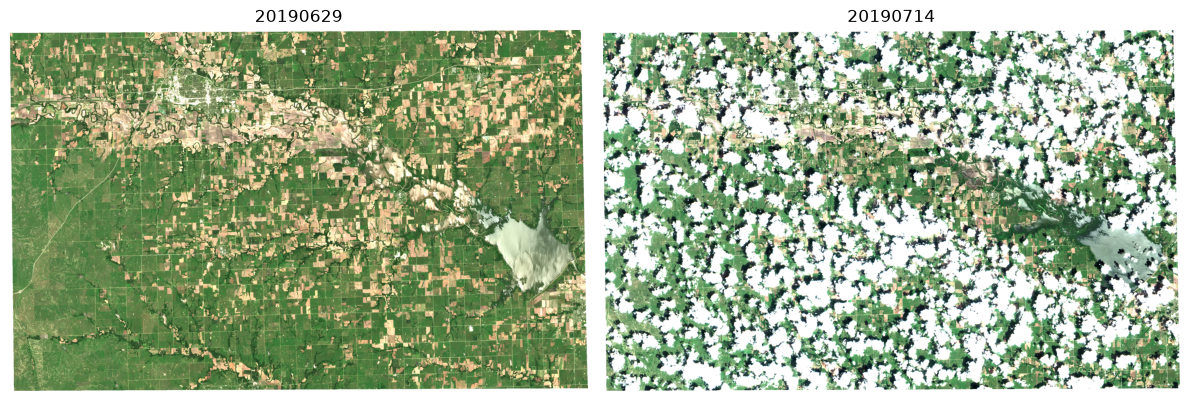

In [14]:
import matplotlib.pyplot as plt

def to_reflectance(dn, offset=-1000, quant=10000):
    dn = dn.astype("float32")
    return np.where(dn == 0, np.nan, (dn + offset) / quant)

def image_grid(n, ncols=2):
    # One panel per date, two per row; hide panels that are not needed
    ncols = min(n, ncols)
    nrows = -(-n // ncols)                                  # n / ncols, rounded up
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_axis_off()
    return fig, axes.flat[:n]

fig, axes = image_grid(len(SCENES))
for ax, date in zip(axes, SCENES):
    f = OUT_DIR / f"S2_T14SQH_{date}_20m.tif"
    if not f.exists():
        ax.set_axis_off(); continue
    with rasterio.open(f) as src:
        rgb = to_reflectance(src.read([3, 2, 1]))          # B04, B03, B02
    rgb = np.clip(rgb / 0.15, 0, 1)                          # same simple stretch for every date
    ax.imshow(np.nan_to_num(np.moveaxis(rgb, 0, -1), nan=1.0))
    ax.set_title(date); ax.set_axis_off()
plt.tight_layout()

**What to notice:** the corners outside the AOI polygon are no data (white here). Using one stretch for all dates keeps them comparable.

## Access data without downloading files

Instead of downloading and clipping whole products, you can read just the AOI straight from the cloud. Both ways below read only the parts of the cloud files that cover the AOI, straight into memory, and save nothing to disk. They differ in how much work they do for you:

- **Streaming** (`rioxarray`) opens **one file at a time** (one band of one date) on that file's own grid. If you want several bands or dates, you open each one and line them up yourself.
- **A data cube** (`odc-stac`) takes **many scenes and bands at once**, resamples them onto one grid you choose, and stacks the dates along a time axis.

### Streaming: read only the AOI from Earth Search (no account)

Here nothing is downloaded in full. `rioxarray` asks the cloud file for the blocks that cover the AOI only.

Note the scaling: the Earth Search items carry `scale = 0.0001` and `offset = -0.1`, so reflectance = value × 0.0001 − 0.1. This is the same as (value − 1000) / 10000 for the `.SAFE` files.

In [15]:
def iso(d):
    return f"{d[:4]}-{d[4:6]}-{d[6:]}"            # "20190719" -> "2019-07-19"

earth_search = Client.open("https://earth-search.aws.element84.com/v1")
search = earth_search.search(
    collections=["sentinel-2-c1-l2a"],
    bbox=AOI_BBOX_LL,
    datetime=f"{iso(min(SCENES))}/{iso(max(SCENES))}",   # first to last date in SCENES
    query={"grid:code": {"eq": "MGRS-14SQH"}},
)
es_items = {}
for item in search.items():
    date = item.datetime.strftime("%Y%m%d")
    if date in SCENES:
        es_items[date] = item
        same = item.properties["s2:product_uri"] == SCENES[date] + ".SAFE"
        print(date, item.id, "| same product as the .SAFE:", same)

C:\Users\gaura\miniforge3\envs\GEOG726\Lib\site-packages\pystac\extensions\storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


20190714 S2B_T14SQH_20190714T172246_L2A | same product as the .SAFE: True
20190629 S2A_T14SQH_20190629T171920_L2A | same product as the .SAFE: True


Read only the AOI part of the red band straight into memory.

In [16]:
import rioxarray

red_asset = es_items[max(es_items)].assets["red"]   # the latest date in SCENES
print(red_asset.href)
print(red_asset.extra_fields["raster:bands"][0])     # nodata, scale, offset

red = rioxarray.open_rasterio(red_asset.href, masked=True).squeeze("band", drop=True)
red_aoi = (red.rio.clip_box(*aoi.total_bounds)       # 1) read only the window around the AOI
              .rio.clip(aoi.geometry, aoi.crs))   # 2) set pixels outside the polygon to no data
print(red_aoi.shape, "pixels at 10 m")
reflectance = red_aoi * 0.0001 - 0.1
print("Mean red reflectance in the AOI:", float(reflectance.mean()))

https://e84-earth-search-sentinel-data.s3.us-west-2.amazonaws.com/sentinel-2-c1-l2a/14/S/QH/2019/7/S2B_T14SQH_20190714T172246_L2A/B04.tif
{'nodata': 0, 'data_type': 'uint16', 'spatial_resolution': 10, 'scale': 0.0001, 'offset': -0.1}
(3734, 5979) pixels at 10 m
Mean red reflectance in the AOI: 0.22988633811473846


### Data cube: all dates and several bands at once (no account)

A data cube is streaming plus automatic alignment and stacking: underneath, it reads the same cloud files the same way. Here all the scenes come from the same tile and UTM zone, so they already line up; the cube saves much more work when an area spans several tiles or UTM zones, or mixes sensors.

`odc-stac` builds one array with dimensions (time, y, x) for each band, on a grid you choose (here 20 m in the AOI's UTM zone). It is **lazy**: nothing is read until you ask for values, such as plotting or `.compute()`.

In [17]:
from odc.stac import load

items = [es_items[d] for d in sorted(es_items)]
cube = load(
    items,
    bands=["blue", "green", "red", "nir08", "swir16", "swir22", "scl"],
    crs="EPSG:32614",
    resolution=20,
    bbox=AOI_BBOX_LL,
    groupby="solar_day",
    chunks={},            # lazy, with Dask
)
cube

<xarray.Dataset> Size: 161MB
Dimensions:      (y: 2027, x: 3052, time: 2)
Coordinates:
  * y            (y) float64 16kB 4.263e+06 4.263e+06 ... 4.223e+06 4.223e+06
  * x            (x) float64 24kB 7.251e+05 7.251e+05 ... 7.861e+05 7.861e+05
  * time         (time) datetime64[us] 16B 2019-06-29T17:23:14.698000 2019-07...
    spatial_ref  int32 4B 32614
Data variables:
    blue         (time, y, x) uint16 25MB dask.array<chunksize=(1, 2027, 3052), meta=np.ndarray>
    green        (time, y, x) uint16 25MB dask.array<chunksize=(1, 2027, 3052), meta=np.ndarray>
    red          (time, y, x) uint16 25MB dask.array<chunksize=(1, 2027, 3052), meta=np.ndarray>
    nir08        (time, y, x) uint16 25MB dask.array<chunksize=(1, 2027, 3052), meta=np.ndarray>
    swir16       (time, y, x) uint16 25MB dask.array<chunksize=(1, 2027, 3052), meta=np.ndarray>
    swir22       (time, y, x) uint16 25MB dask.array<chunksize=(1, 2027, 3052), meta=np.ndarray>
    scl          (time, y, x) uint8 12MB dask.array<chunksize=(1, 2027, 3052), meta=np.ndarray>

Show one band.

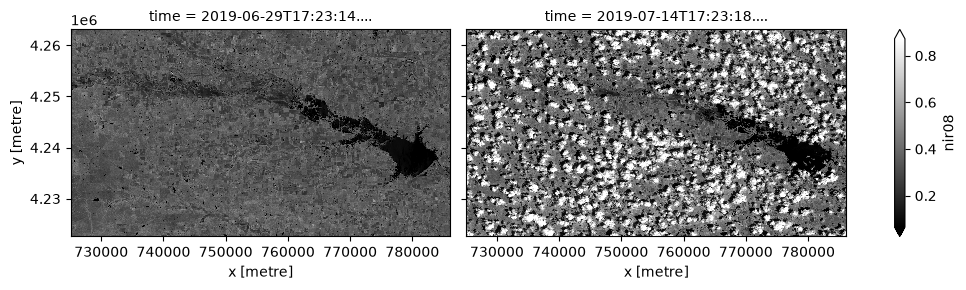

In [18]:
# Example: one band, all dates, actually read now
nir = cube["nir08"].where(cube["nir08"] != 0) * 0.0001 - 0.1
nir.plot(col="time", col_wrap=2, robust=True, cmap="gray", size=3, aspect=1.6);

Show the cube as true-color images, the same way as the clipped files in *Check the results*: bands B04, B03, B02 as red, green, blue, converted to reflectance, with the same stretch for all dates. Earth Search stores the bands with scale 0.0001 and offset −0.1 (0 = no data), which gives the same reflectance as the `(DN − 1000) / 10000` used for the `.SAFE` files.

C:\Users\gaura\miniforge3\envs\GEOG726\Lib\site-packages\rasterio\warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


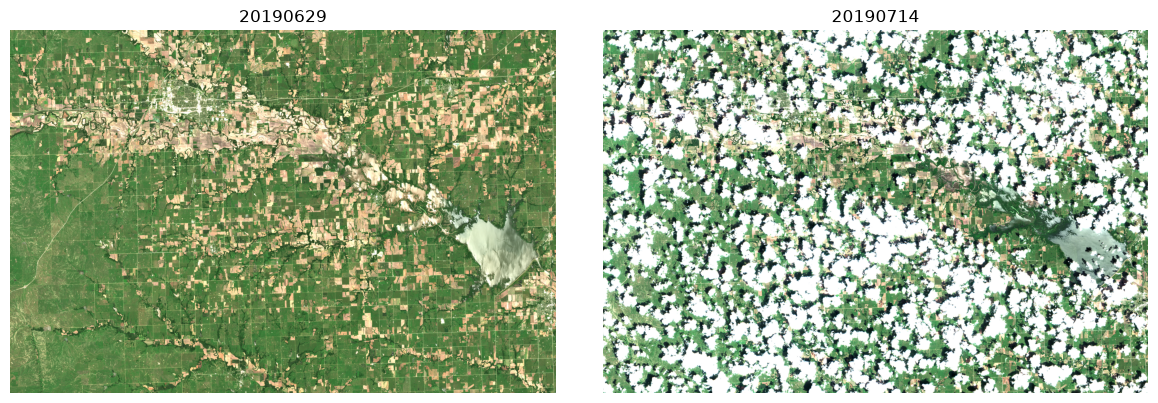

In [19]:
import numpy as np
import matplotlib.pyplot as plt

rgb_cube = cube[["red", "green", "blue"]].to_array("band")     # (band, time, y, x): B04, B03, B02
rgb_cube = rgb_cube.where(rgb_cube != 0) * 0.0001 - 0.1         # DN -> reflectance, 0 = no data
rgb_cube = rgb_cube.compute()                                   # read the three bands from the cloud now

fig, axes = image_grid(rgb_cube.sizes["time"])                  # image_grid() is defined in "Check the results"
for ax, t in zip(axes, rgb_cube.time.values):
    rgb = np.clip(rgb_cube.sel(time=t).values / 0.15, 0, 1)   # same simple stretch for every date
    ax.imshow(np.nan_to_num(np.moveaxis(rgb, 0, -1), nan=1.0))
    ax.set_title(str(t)[:10].replace("-", "")); ax.set_axis_off()
plt.tight_layout()

**What to notice:** the images match the clipped files, except at the corners: the cube covers the AOI's bounding box, not the AOI polygon, so it has no no-data corners. To mask the cube to the polygon as well, use `rgb_cube.rio.write_crs(cube.rio.crs).rio.clip(aoi.to_crs(cube.rio.crs).geometry)`.

#### Save the data cube to a file

A data cube can be saved in two formats that keep the time dimension (a GeoTIFF cannot):

- **NetCDF** (`.nc`): one file holding all bands and dates, widely used for climate and Earth-science data.
- **Zarr** (`.zarr`): a folder of many small compressed chunks, designed for cloud storage and parallel reading.

Saving is when the lazy cube is actually read from the cloud, so the next cell first loads it into memory once with `.compute()` and then writes both files from memory. The values stay as stored 16-bit integers, not reflectance. Reopen the files with `decode_coords="all"` so the coordinate system comes back.

In [20]:
import xarray as xr

nc_file = OUT_DIR / "cube_20m.nc"
zarr_dir = OUT_DIR / "cube_20m.zarr"

cube_mem = cube.compute()          # read everything from the cloud once (about 300 MB)
cube_mem = cube_mem.rio.write_crs(cube_mem.rio.crs)   # store the coordinate system so both formats keep it

# NetCDF: one compressed file
encoding = {v: {**cube_mem[v].encoding, "zlib": True, "complevel": 4} for v in cube_mem.data_vars}   # keep existing settings, add compression
cube_mem.to_netcdf(nc_file, encoding=encoding)

# Zarr: a folder of compressed chunks
cube_mem.chunk({"time": 1, "y": 512, "x": 512}).to_zarr(zarr_dir, mode="w", consolidated=False)

def folder_size(path):
    return sum(f.stat().st_size for f in path.rglob("*") if f.is_file())

print(f"In memory: {cube_mem.nbytes / 1e6:6.1f} MB")
print(f"NetCDF:    {nc_file.stat().st_size / 1e6:6.1f} MB  ({nc_file.name})")
print(f"Zarr:      {folder_size(zarr_dir) / 1e6:6.1f} MB  ({zarr_dir.name}, {sum(1 for _ in zarr_dir.rglob('*') if _.is_file())} files)")

In memory:  160.9 MB
NetCDF:      99.9 MB  (cube_20m.nc)
Zarr:       121.2 MB  (cube_20m.zarr, 351 files)


Reopen and check the files.

In [21]:
# Reopen both and check they hold the same data, grid and coordinate system
cube_nc = xr.open_dataset(nc_file, decode_coords="all")
cube_zarr = xr.open_zarr(zarr_dir, decode_coords="all", consolidated=False)

print("CRS:", cube_nc.rio.crs, "|", cube_zarr.rio.crs)
print("Dimensions:", dict(cube_nc.sizes))
print("Same values as the cube:", bool((cube_nc == cube_mem).all().to_array().all()),
      bool((cube_zarr == cube_mem).all().to_array().all()))
cube_nc.close()

CRS: EPSG:32614 | EPSG:32614
Dimensions: {'time': 2, 'y': 2027, 'x': 3052}
Same values as the cube: True True


## Questions

Answer each question in the cell below it, in one to three sentences. Use the outputs above.

**Q1.** How did you download the two products (by hand or with code)? What, if anything, went wrong, and how did you fix it? (Write "nothing" if it all worked.)

I downloaded the product with code and there was no any error during the downloading process however i found error while clipping. The error was: RasterioIOError:

'sentinel2\S2A_MSIL2A_20190629T170901_N0500_R112_T14SQH_20230712T025844.SAFE\GRANULE\L2A_T14SQH_A020987_20190629T171920\IMG_DATA\R20m\T14SQH_20190629T170901_B02_20m.jp2' not recognized as being in a supported file format. It could have been recognized by driver JP2OpenJPEG, but plugin gdal_JP2OpenJPEG.dll is not available in your installation. You may install it with 'conda install -c conda-forge libgdal-jp2openjpeg'

I then solved the error by installing the package: 

#conda install -c conda-forge libgdal-jp2openjpeg 

**Q2.** From the *Which time is the image time?* output, give the tile's `SENSING_TIME` for June 29. How many minutes after the start of the datatake (the time in the product name) was this tile imaged, and why is there a gap?


The Tile_SENSING_TIME for June 29 is 2019‑06‑29T17:23:14.69854Z.
The Datatake start was 2019‑06‑29T17:09:01.024Z 

Computing the difference between the two times: **14min and 13.674 seconds**

The gap happens because Sentinel-2 captures a long continuous strip of Earth (a datatake) in a single pass, while individual image tiles (granules) cover only a specific section of that strip


**Q3.** In the *Check the results* output, the clipped files are smaller on disk than in memory. Why?

*The GeoTIFFs on disk are compressed (e.g., DEFLATE/LZW), while the arrays in memory are uncompressed, with every pixel stored at full size. Neighboring pixels in a reflectance image have similar values, so they compress well. Any nodata areas outside the clip boundary are all one value and compress almost to nothing. The in-memory copy may also use a larger data type than the file. For example, the file stores uint16, but reading with masking or scaling turns it into float32/float64, which is 2–4× more bytes per pixel.*

**Q4.** Compare the June 29 and July 14 true-color images. What do clouds and cloud shadows look like on July 14, and why would statistics computed over all of its pixels be misleading? (Hint: think about what a quality layer such as the SCL is for.)

*On July 14, clouds appear as bright white patches with high reflectance in all visible bands. Cloud shadows are dark patches next to them, offset in the direction opposite the sun (toward the north/northwest at this time of day) and shaped like the clouds that cast them. Statistics over all pixels would be misleading because these pixels aren’t showing the surface. Clouds push mean reflectance up, shadows push it down, and indices like NDVI get distorted (clouds give values near zero, so vegetation looks less healthy). Differences between the two dates would then reflect the weather, not real land-surface change. The SCL (Scene Classification Layer) labels each pixel as cloud (medium/high probability), thin cirrus, cloud shadow, vegetation, water, and so on, so you can mask the bad pixels before computing statistics.*

**Q5.** The data cube's grid (the `y` and `x` sizes in the cube printout) is larger than the clipped 20 m files (1868 rows × 2990 columns), even though both are 20 m pixels in the same UTM zone. Why? (Hint: look at the `bbox` the cube was loaded with.)

*The cube was built from its own bbox, not from the clip boundary, so it covers a larger area. The bbox is given in geographic coordinates (lon/lat), and a lon/lat rectangle doesn’t map to a neat rectangle in UTM: it becomes a slightly rotated, distorted shape. The cube’s grid is the UTM rectangle that fully encloses that shape, which adds extra rows and columns. Snapping to the 20 m grid can also add a pixel at the edges. So at the same 20 m resolution, the cube has more rows and columns than the 1868 × 2990 clipped files.*

**Q6.** For your own project topic from Lab 1, would you download files or read the data without downloading? Why?

*For my urban heat island (UHI) project in Little Rock, I would read the data without downloading, using STAC with cloud-optimized GeoTIFFs. Little Rock covers only a small part of a 100 × 100 km Sentinel-2 tile, so a bbox read gets just my study area instead of the full tile. UHI analysis also needs many dates (several summers, and ideally different seasons to compare), and for each date I only need a few bands: red and NIR for NDVI, SWIR for NDBI/built-up area, and SCL for masking clouds. Reading without downloading lets me filter scenes by date and cloud cover first, then load only those bands for my area into a data cube. That saves a lot of storage and time compared with downloading full SAFE products. One limitation is that Sentinel-2 has no thermal band, so for land surface temperature I would pull Landsat 8/9 thermal data through the same STAC approach. I would download files only if I needed to work offline or reprocess the same scenes many times.*